# 01 — EDA: days to the next oil change (Task 2.1)

Data: `data/synthetic/service_records_cleaned.csv` — **SYNTHETIC** (task 1.3 generator,
cleaned by task 1.4). Every number here describes the synthetic rules, not real customers.

Features come from `src/common/features.py` (the same code the API will use, R8); target and
split from `src/ml/dataset.py`. Charts are saved to `docs/figures/eda_*.png` for slides 3–4.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")  # run from the repo root so config paths work

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.ml.dataset import TARGET, build_dataset, load_ml_config, make_split
from src.ml.baselines import predict_b1
%matplotlib inline
# ^ after the imports: src.ml.baselines switches matplotlib to file-only mode (Agg)

cfg = load_ml_config()
df, routes = build_dataset(cfg)
split = make_split(df, cfg)
FIG = Path(cfg["figures_dir"])

# Reference palette (dataviz skill, light surface)
SURFACE, TEXT, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"

def style(ax, grid_axis="y"):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, facecolor=SURFACE, metadata={"Software": None})
    plt.show()

has_y = df[df[TARGET].notna()]
print(f"visits {len(df):,} | with target {len(has_y):,} | trucks {df[cfg['vehicle_col']].nunique()}")
print(f"split: cutoff {split.cutoff:%Y-%m-%d}, train {len(split.train):,} visits, test {len(split.test):,} visits")

visits 3,845 | with target 3,345 | trucks 500
split: cutoff 2025-08-23, train 1,745 visits, test 202 visits


## 1. The target
Days from a visit to the same truck's next visit. Each truck's last visit has no target.

count    3345.0
mean       59.6
std        16.2
min        20.0
25%        48.0
50%        58.0
75%        70.0
max       132.0


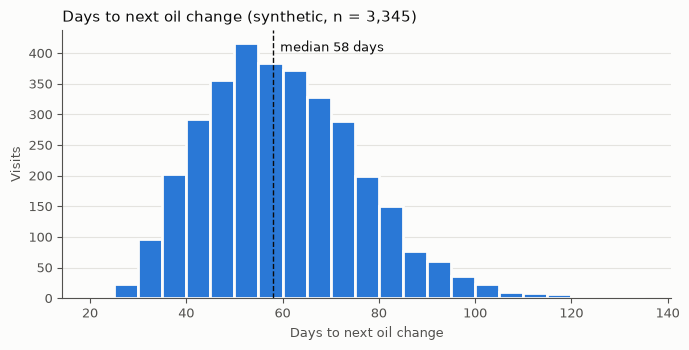

In [2]:
y = has_y[TARGET]
print(y.describe().round(1).to_string())
fig, ax = plt.subplots(figsize=(7, 3.6), facecolor=SURFACE)
ax.hist(y, bins=np.arange(y.min() // 5 * 5, y.max() + 5, 5), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(y.median(), color=TEXT, linewidth=1, linestyle="--")
ax.text(y.median() + 1.5, ax.get_ylim()[1] * 0.92, f"median {y.median():.0f} days", color=TEXT, fontsize=9)
ax.set_xlabel("Days to next oil change", color=MUTED, fontsize=9)
ax.set_ylabel("Visits", color=MUTED, fontsize=9)
ax.set_title(f"Days to next oil change (synthetic, n = {len(y):,})", color=TEXT, fontsize=11, loc="left")
style(ax)
save(fig, "eda_target_distribution.png")

## 2. Destination: a weak signal
If distance drove the interval, far destinations (Beijing) would have much shorter gaps in
days (more km per day). The orange marks show what the formula B1 expects.

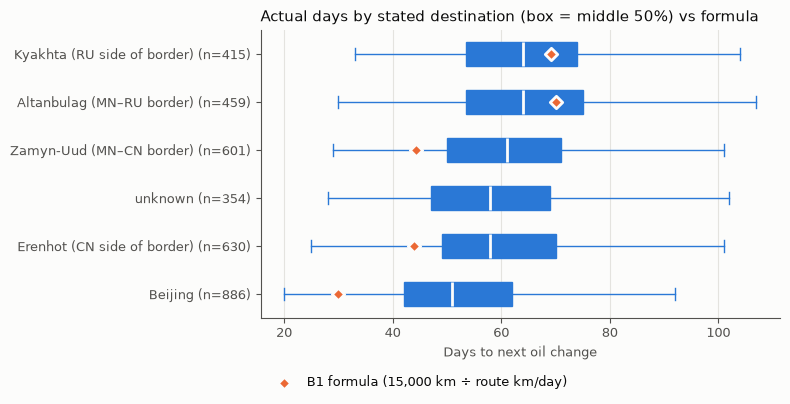

                             size  median
destination_name                         
Altanbulag (MN–RU border)     459    64.0
Beijing                       886    51.0
Erenhot (CN side of border)   630    58.0
Kyakhta (RU side of border)   415    64.0
Zamyn-Uud (MN–CN border)      601    61.0
unknown                       354    58.0


In [3]:
order = has_y.groupby("destination_name")[TARGET].median().sort_values().index.tolist()
data = [has_y.loc[has_y["destination_name"] == d, TARGET] for d in order]
fig, ax = plt.subplots(figsize=(8, 4.2), facecolor=SURFACE)
ax.boxplot(data, orientation="horizontal", widths=0.5, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor=BLUE, edgecolor=BLUE), medianprops=dict(color=SURFACE, linewidth=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
km = cfg["baselines"]["b1_interval_km"]
b1 = [km / routes[d].km_per_day if d in routes else np.nan for d in order]
ax.scatter(b1, range(1, len(order) + 1), marker="D", s=40, color=ORANGE, zorder=3,
           edgecolors=SURFACE, linewidths=2, label=f"B1 formula ({km:,} km ÷ route km/day)")
ax.set_yticks(range(1, len(order) + 1), [f"{d} (n={len(x)})" for d, x in zip(order, data)])
ax.set_xlabel("Days to next oil change", color=MUTED, fontsize=9)
ax.set_title("Actual days by stated destination (box = middle 50%) vs formula", color=TEXT, fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, labelcolor=TEXT, loc="upper left", bbox_to_anchor=(0, -0.16))
style(ax, "x")
save(fig, "eda_days_by_destination.png")
print(has_y.groupby("destination_name")[TARGET].agg(["size", "median"]).round(0).to_string())

## 3. The truck's own history
History features use only EARLIER visits (first visit → empty). Shown for visits with ≥ 2
earlier visits so the history is not a single number.

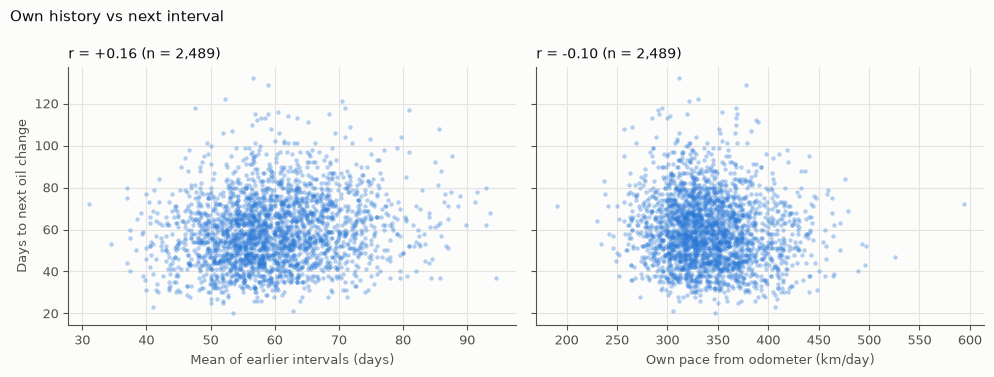

past_interval_mean_days    0.16
km_per_day_hist           -0.10
past_late_share            0.14
days_since_prev_visit      0.10
days_to_next_change        1.00


In [4]:
h = has_y[has_y["n_prior_visits"] >= 2]
panels = (("past_interval_mean_days", "Mean of earlier intervals (days)"),
          ("km_per_day_hist", "Own pace from odometer (km/day)"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), facecolor=SURFACE, sharey=True)
for ax, (col, label) in zip(axes, panels):
    d = h[[col, TARGET]].dropna()
    r = d[col].corr(d[TARGET])
    ax.scatter(d[col], d[TARGET], s=10, color=BLUE, alpha=0.35, linewidths=0)
    ax.set_xlabel(label, color=MUTED, fontsize=9)
    ax.set_title(f"r = {r:+.2f} (n = {len(d):,})", color=TEXT, fontsize=10, loc="left")
    style(ax, "both")
axes[0].set_ylabel("Days to next oil change", color=MUTED, fontsize=9)
fig.suptitle("Own history vs next interval", color=TEXT, fontsize=11, x=0.01, ha="left")
save(fig, "eda_history_vs_target.png")
print(h[["past_interval_mean_days", "km_per_day_hist", "past_late_share", "days_since_prev_visit", TARGET]]
      .corr()[TARGET].round(2).to_string())

## 4. Lateness history
Late interval = more than 20,000 km driven between two visits (D-030 / D-047).

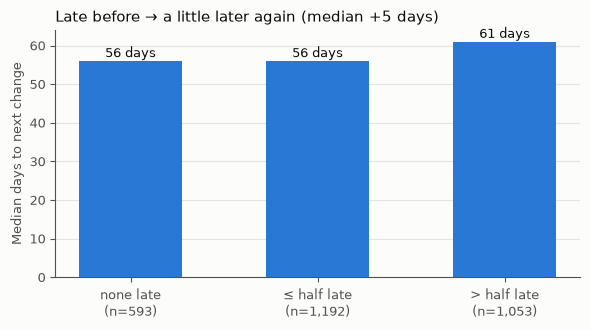

                 size  median
past_late_share              
none late         593    56.0
≤ half late      1192    56.0
> half late      1053    61.0 
no lateness history (first visit / missing odometer): 507


In [5]:
bins = pd.cut(has_y["past_late_share"], [-0.01, 0, 0.5, 1.0], labels=["none late", "≤ half late", "> half late"])
g = has_y.groupby(bins, observed=True)[TARGET].agg(["size", "median"])
fig, ax = plt.subplots(figsize=(6, 3.4), facecolor=SURFACE)
ax.bar(range(len(g)), g["median"], color=BLUE, width=0.55)
for i, (n, m) in enumerate(zip(g["size"], g["median"])):
    ax.text(i, m + 1, f"{m:.0f} days", ha="center", color=TEXT, fontsize=9)
ax.set_xticks(range(len(g)), [f"{lab}\n(n={n:,})" for lab, n in zip(g.index, g["size"])])
ax.set_ylabel("Median days to next change", color=MUTED, fontsize=9)
ax.set_title(f"Late before → a little later again (median +{g['median'].iloc[-1] - g['median'].iloc[0]:.0f} days)", color=TEXT, fontsize=11, loc="left")
style(ax)
save(fig, "eda_lateness_history.png")
print(g.to_string(), "\nno lateness history (first visit / missing odometer):", has_y["past_late_share"].isna().sum())

## 5. Season of the service

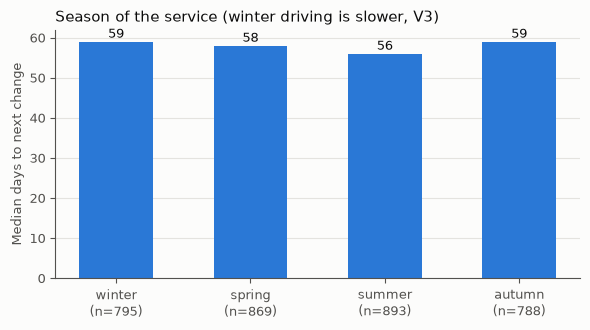

In [6]:
seasons = ["winter", "spring", "summer", "autumn"]
g = has_y.groupby("season")[TARGET].agg(["size", "median"]).reindex(seasons)
fig, ax = plt.subplots(figsize=(6, 3.4), facecolor=SURFACE)
ax.bar(range(4), g["median"], color=BLUE, width=0.55)
for i, m in enumerate(g["median"]):
    ax.text(i, m + 1, f"{m:.0f}", ha="center", color=TEXT, fontsize=9)
ax.set_xticks(range(4), [f"{s}\n(n={n:,})" for s, n in zip(seasons, g["size"])])
ax.set_ylabel("Median days to next change", color=MUTED, fontsize=9)
ax.set_title("Season of the service (winter driving is slower, V3)", color=TEXT, fontsize=11, loc="left")
style(ax)
save(fig, "eda_season.png")

## 6. Missing data after cleaning
Cleaning keeps missing values empty (D-048); features must cope with them.

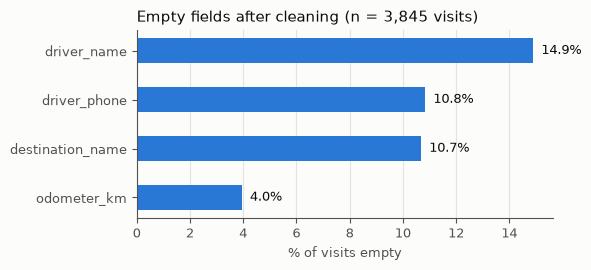

history features empty: {'past_interval_mean_days': 500, 'km_per_day_hist': 542, 'past_late_share': 567}


In [7]:
raw = pd.read_csv(cfg["input"])
cols = ["destination_name", "odometer_km", "driver_name", "driver_phone"]
miss = raw[cols].isna().mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(6, 2.8), facecolor=SURFACE)
ax.barh(range(len(miss)), miss.values, color=BLUE, height=0.5)
for i, v in enumerate(miss.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color=TEXT, fontsize=9)
ax.set_yticks(range(len(miss)), miss.index)
ax.set_xlabel("% of visits empty", color=MUTED, fontsize=9)
ax.set_title(f"Empty fields after cleaning (n = {len(raw):,} visits)", color=TEXT, fontsize=11, loc="left")
style(ax, "x")
save(fig, "eda_missing.png")
print("history features empty:", df[["past_interval_mean_days", "km_per_day_hist", "past_late_share"]].isna().sum().to_dict())

## Findings (synthetic data)
- The target is centred near two months with a long right tail (late customers).
- Destination separates trucks much less than the B1 formula expects — trucks change route
  between oil changes and waiting days weigh as much as distance (D-047). B1 will suffer.
- A truck's own history (earlier intervals, lateness, pace) carries some signal, but each
  feature alone is weak; the model (2.3b) has to combine them.
- Destination is empty on ~11 % of visits → B1 falls back to B0 there.